# Case OrbitShop — Análise de dados

Notebook que reproduz os numeros do memo. Execute de cima para baixo.

**Convenções**
- **Taxa de cancelamento** = pedidos cancelados ÷ total de pedidos do período (pela data do pedido).
- **Valores em R$** usam `valor_total` da tabela Pedidos (justificativa na Q6).

## 0. Carregando os dados

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

ARQUIVO = "Base_Dados_OrbitShop.xlsx"

clientes   = pd.read_excel(ARQUIVO, sheet_name="Clientes")
produtos   = pd.read_excel(ARQUIVO, sheet_name="Produtos")
pedidos    = pd.read_excel(ARQUIVO, sheet_name="Pedidos")
itens      = pd.read_excel(ARQUIVO, sheet_name="Itens_Pedido")
tickets    = pd.read_excel(ARQUIVO, sheet_name="Tickets_Suporte")
avaliacoes = pd.read_excel(ARQUIVO, sheet_name="Avaliacoes")

# Datas
pedidos["data_pedido"] = pd.to_datetime(pedidos["data_pedido"])
tickets["data_abertura"] = pd.to_datetime(tickets["data_abertura"])
avaliacoes["data_avaliacao"] = pd.to_datetime(avaliacoes["data_avaliacao"])

# Colunas auxiliares
pedidos["ano"] = pedidos["data_pedido"].dt.year
pedidos["mes"] = pedidos["data_pedido"].dt.to_period("M")
pedidos["cancelado"] = pedidos["status"] == "cancelado"

# Cores dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#b8b7b2"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

### Checagem rápida da base

In [2]:

tabelas = {"Clientes": clientes, "Produtos": produtos, "Pedidos": pedidos,
           "Itens_Pedido": itens, "Tickets_Suporte": tickets, "Avaliacoes": avaliacoes}

for nome, df in tabelas.items():
    nulos = df.isna().sum()
    print(f"{nome}: {len(df):,} linhas | id único: {df['id'].is_unique} | nulos: {nulos[nulos > 0].to_dict()}")

Clientes: 3,000 linhas | id único: True | nulos: {}
Produtos: 200 linhas | id único: True | nulos: {}
Pedidos: 15,000 linhas | id único: True | nulos: {'valor_total': 79}
Itens_Pedido: 36,740 linhas | id único: True | nulos: {'desconto_aplicado': 301}
Tickets_Suporte: 4,000 linhas | id único: True | nulos: {'data_resolucao': 1653}
Avaliacoes: 8,000 linhas | id único: True | nulos: {'comentario': 1679}


In [3]:

# Todas as chaves estrangeiras existem na tabela de origem?
print("Pedidos sem cliente:  ", (~pedidos["cliente_id"].isin(clientes["id"])).sum())
print("Itens sem pedido:     ", (~itens["pedido_id"].isin(pedidos["id"])).sum())
print("Itens sem produto:    ", (~itens["produto_id"].isin(produtos["id"])).sum())
print("Tickets sem pedido:   ", (~tickets["pedido_id"].isin(pedidos["id"])).sum())
print("Avaliações sem pedido:", (~avaliacoes["pedido_id"].isin(pedidos["id"])).sum())

Pedidos sem cliente:   0
Itens sem pedido:      0
Itens sem produto:     0
Tickets sem pedido:    0
Avaliações sem pedido: 0


In [4]:
# Preenchendo os 301 descontos vazios.
# preco_praticado já é o preço de catálogo com desconto, então: desconto = 1 − praticado ÷ catálogo
itens = itens.merge(produtos[["id", "preco_unitario"]], left_on="produto_id", right_on="id",
                    suffixes=("", "_produto")).drop(columns="id_produto")
desconto_calculado = (1 - itens["preco_praticado"] / itens["preco_unitario"]).round(2)
itens["desconto_aplicado"] = itens["desconto_aplicado"].fillna(desconto_calculado)

# Valor de cada item = quantidade * preço praticado
itens["valor_item"] = itens["quantidade"] * itens["preco_praticado"]
print("Descontos vazios após preenchimento:", itens["desconto_aplicado"].isna().sum())

Descontos vazios após preenchimento: 0


Aqui as chaves entre as tabelas estão íntegras. Ainda existem campos vazios, sendo eles:
- `valor_total` em 79 pedidos, desconsiderei nas contas mais pra frente;
- `data_resolucao` e `comentario`, mas são vazios esperados por conta dos tickets não resolvidos e avaliações sem texto.

## Q1. Três perguntas para a Camila e o Rogério

*(Respondida antes de olhar os dados.)*

a. Quais filtros e definições entraram no cálculo de cancelamento?
b. Qual período e data de referência compararam 2023 e 2024?
c. O histórico é recalculado quando um pedido muda de status?

## Q2. Distribuição dos pedidos por status

In [5]:
# Tabela: quantidade e % por status, no total e em cada ano
tabela_status = pd.DataFrame({
    "pedidos": pedidos["status"].value_counts(),
    "% total": pedidos["status"].value_counts(normalize=True) * 100,
})

pct_ano = pd.crosstab(pedidos["status"], pedidos["ano"], normalize="columns") * 100
tabela_status["% 2023"] = pct_ano[2023]
tabela_status["% 2024"] = pct_ano[2024]
tabela_status.round(1)

,pedidos,% total,% 2023,% 2024
status,,,,
entregue,9959,66.4,66.3,66.5
cancelado,2537,16.9,16.8,17.1
em_transito,1371,9.1,9.4,8.8
devolvido,1133,7.6,7.5,7.6


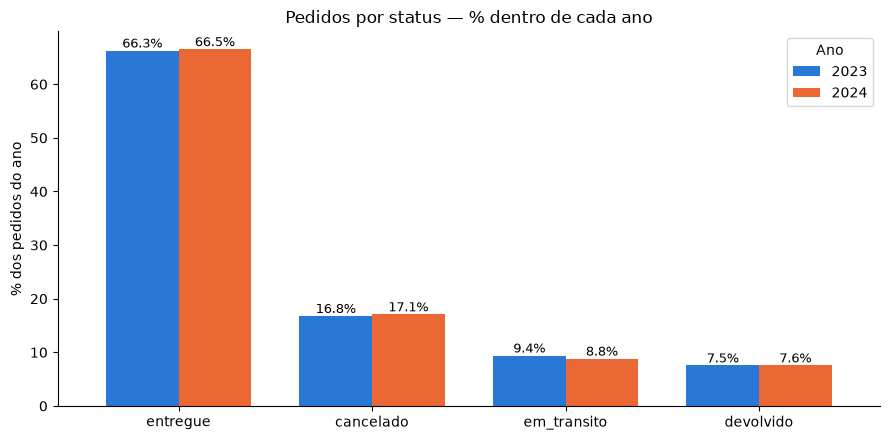

In [6]:
# Gráfico: % de cada status dentro de cada ano (2023 x 2024)
ordem = ["entregue", "cancelado", "em_transito", "devolvido"]
dados = pct_ano.loc[ordem]

ax = dados.plot.bar(color=[AZUL, LARANJA], width=0.75, figsize=(9, 4.5), rot=0)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", fontsize=9)
ax.set_title("Pedidos por status — % dentro de cada ano")
ax.set_ylabel("% dos pedidos do ano")
ax.set_xlabel("")
ax.legend(title="Ano")
plt.tight_layout()
plt.show()

In [7]:
# Verificando as frases ditas pela Camila e Rogério
resumo_ano = pedidos.groupby("ano").agg(
    pedidos=("id", "count"),
    cancelados=("cancelado", "sum"),
)
resumo_ano["taxa (%)"] = resumo_ano["cancelados"] / resumo_ano["pedidos"] * 100

# Mesma taxa, mas excluindo os pedidos ainda "em trânsito" do denominador
finalizados = pedidos[pedidos["status"] != "em_transito"]
resumo_ano["taxa s/ finalizados (%)"] = finalizados.groupby("ano")["cancelado"].mean() * 100
resumo_ano.round(1)

,pedidos,cancelados,taxa (%),taxa s/ finalizados (%)
ano,,,,
2023,8386,1407,16.8,18.5
2024,6614,1130,17.1,18.7


**Resposta**

A tabela e o gráfico mostram que dois em cada três pedidos da OrbitShop são entregues e que um em cada seis (16,9%) termina cancelado, o que confirma o numero levantado pelo fundo. Somando as devoluções (7,6%), cerca de um em cada quatro pedidos não se converte em venda.

O gráfico de barras deixa claro que essa distribuição quase não muda de um ano para o outro. A taxa de cancelamento passou de 16,8% em 2023 para 17,1% em 2024, uma variação de apenas 0,3 ponto percentual. Por isso, olhando a base inteira, nenhum dos dois executivos esta certo. Ao contrário do aumento de 40% citado pela Camila, o número absoluto de cancelamentos caiu 20% (de 1.407 para 1.130), e a taxa ficou estável. Já o "18%" do Rogério aparece quando os pedidos em trânsito são retirados do cálculo, como mostra a coluna "taxa s/ finalizados". Mas nessa mesma conta 2023 fica em 18,5% e 2024 em 18,7%, então também não houve a queda que ele aponta.

A última tabela ajuda a entender a confusão. Há 788 pedidos feitos em 2023 que ainda aparecem como "em trânsito", mais de um ano depois da compra. Isso indica um status desatualizado no sistema e explica por que relatórios que usam denominadores diferentes chegam a taxas diferentes (16,9% considerando todos os pedidos e 18,6% considerando só os finalizados). Por fim, 2023 tem mais pedidos que 2024, diferença que investigo na Q5.

## Q3. Categorias que mais vendem

Considerando receita = quantidade * preço praticado, somada por categoria apenas para pedidos não cancelados.

In [8]:
vendas = (itens
          .merge(produtos[["id", "categoria"]], left_on="produto_id", right_on="id", suffixes=("", "_prod"))
          .merge(pedidos[["id", "status"]], left_on="pedido_id", right_on="id", suffixes=("", "_ped")))
vendas = vendas[vendas["status"] != "cancelado"]

categorias = vendas.groupby("categoria").agg(receita=("valor_item", "sum"), unidades=("quantidade", "sum"))
categorias["% receita"] = categorias["receita"] / categorias["receita"].sum() * 100
categorias["% unidades"] = categorias["unidades"] / categorias["unidades"].sum() * 100
categorias["preço médio por unidade"] = categorias["receita"] / categorias["unidades"]
categorias["rank receita"] = categorias["receita"].rank(ascending=False).astype(int)
categorias["rank volume"] = categorias["unidades"].rank(ascending=False).astype(int)
categorias.sort_values("rank receita").round(1)

,receita,unidades,% receita,% unidades,preço médio por unidade,rank receita,rank volume
categoria,,,,,,,
Eletrônicos,27250217.0,15521,18.5,17.0,1755.7,1,1
Casa & Decoração,21810340.7,14850,14.8,16.2,1468.7,2,2
Beleza & Saúde,20838983.2,11507,14.2,12.6,1811.0,3,4
Esporte & Lazer,18071566.5,10214,12.3,11.2,1769.3,4,5
Moda,17515594.4,12943,11.9,14.1,1353.3,5,3
Livros & Papelaria,16232400.0,9093,11.0,9.9,1785.2,6,6
Bebês & Crianças,13501400.0,8672,9.2,9.5,1556.9,7,8
Alimentos & Bebidas,11742478.6,8691,8.0,9.5,1351.1,8,7


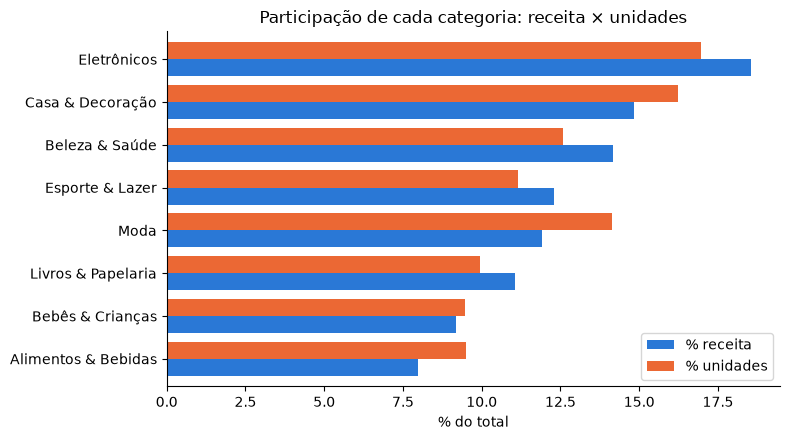

In [9]:
ordem = categorias.sort_values("% receita").index
ax = categorias.loc[ordem, ["% receita", "% unidades"]].plot.barh(color=[AZUL, LARANJA], figsize=(8, 4.5), width=0.8)
ax.set_title("Participação de cada categoria: receita × unidades")
ax.set_xlabel("% do total")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Resposta**

As categorias que mais vendem são Eletrônicos e Casa & Decoração, que ocupam o primeiro e o segundo lugar tanto em receita quanto em volume de unidades. As duas listas, porém, não coincidem por inteiro, e a tabela mostra que a diferença aparece no meio e no fim do ranking.

O motivo é o preço medio de cada categoria. Moda é a terceira em unidades vendidas, mas cai para quinta em receita, porque seus produtos custam em média cerca de R$1.350, um dos menores valores da base. Com Beleza & Saúde acontece o contrario. Ela é apenas a quarta em volume, mas sobe para terceira em receita, já que o preço médio fica perto de R$1.810. O mesmo efeito explica por que Bebês & Crianças e Alimentos & Bebidas trocam de posição nos dois últimos lugares. No gráfico, isso aparece nas categorias em que a barra de unidades é maior que a de receita (produtos mais baratos) ou o contrário (produtos mais caros).

Em resumo, quem vende muitas unidades baratas se destaca em volume, e quem vende produtos mais caros ganha espaço em receita. Vale uma ressalva sobre esses valores. Os preços do catálogo parecem pouco relaistas para algumas categorias, com camisetas a R$2.919 e alimentos custando em média R$1.470, então seria bom confirmar o catálogo antes de apresentar esses números. Além disso, como mostro na Q6, a soma dos itens não bate com o valor dos pedidos, por isso a receita por categoria deve ser lida como proporção e não como valor absoluto.

## Q4. Cancelamento e ticket médio

In [10]:
ped_cli = pedidos.merge(clientes[["id", "canal_aquisicao", "segmento"]],
                        left_on="cliente_id", right_on="id", suffixes=("", "_cliente"))

canais = ped_cli.groupby("canal_aquisicao").agg(
    pedidos=("id", "count"),
    cancelados=("cancelado", "sum"),
    ticket_medio=("valor_total", "mean"),
)
canais["taxa cancelamento (%)"] = canais["cancelados"] / canais["pedidos"] * 100
canais["% dos cancelamentos"] = canais["cancelados"] / canais["cancelados"].sum() * 100
canais.sort_values("taxa cancelamento (%)", ascending=False).round(1)

,pedidos,cancelados,ticket_medio,taxa cancelamento (%),% dos cancelamentos
canal_aquisicao,,,,,
paid_search,3965,1219,2553.5,30.7,48.0
indicação,3658,453,2566.0,12.4,17.9
orgânico,3616,426,2521.1,11.8,16.8
redes_sociais,3761,439,2657.2,11.7,17.3


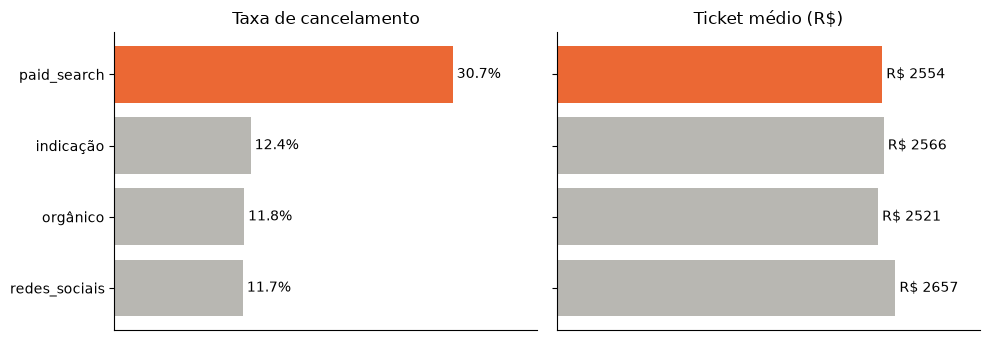

In [11]:
t = canais.sort_values("taxa cancelamento (%)")
cores = [LARANJA if c == "paid_search" else CINZA for c in t.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
b = axes[0].barh(t.index, t["taxa cancelamento (%)"], color=cores)
axes[0].bar_label(b, fmt=" %.1f%%")
axes[0].set_title("Taxa de cancelamento")
b = axes[1].barh(t.index, t["ticket_medio"], color=cores)
axes[1].bar_label(b, fmt=" R$ %.0f")
axes[1].set_title("Ticket médio (R$)")
for ax in axes:
    ax.set_xticks([])
    ax.margins(x=0.25)
plt.tight_layout()
plt.show()

In [12]:
# Verificando se o resultado muda conforme B2B ou B2C em cada ano
pd.concat([
    pd.crosstab(ped_cli["canal_aquisicao"], ped_cli["segmento"], values=ped_cli["cancelado"], aggfunc="mean"),
    pd.crosstab(ped_cli["canal_aquisicao"], ped_cli["ano"], values=ped_cli["cancelado"], aggfunc="mean"),
], axis=1).mul(100).round(1)

,B2B,B2C,2023,2024
canal_aquisicao,,,,
indicação,11.7,12.6,13.2,11.4
orgânico,11.8,11.8,12.0,11.5
paid_search,32.4,30.3,29.8,31.9
redes_sociais,12.2,11.5,11.3,12.1


**Resposta**

Sim, um canal se destaca muito. Os clientes que chegaram pela OrbitShop via `paid_search` (mídia paga em buscadores) cancelam 30,7% dos pedidos, enquanto nos outros três canais a taxa fica entre 11,7% e 12,4%. Isso significa que eles cancelam cerca de 2,6 vezes mais. Como esse canal tem 26% dos pedidos, ele acaba respondendo por 48% de todos os cancelamentos da empresa, quase metade.

O ticket médio, por outro lado, é praticamente o mesmo em todos os canias, perto de R$2.550, como mostra o gráfico da direita. Ou seja, os clientes de paid search não fazem pedidos maiores nem menores que os outros. A última tabela confirma que o padrão não depende de um grupo específico, porque a taxa de cancelamento do paid search fica acima de 30% tanto em B2B quanto em B2C, e tanto em 2023 quanto em 2024.

Juntando essas informaçoes, o problema não parece ser preço nem tamanho do pedido, e sim o perfil do cliente que a mídia paga atrai. Algumas hipóteses são anúncios que prometem algo que o site não entrega (preço, prazo ou produto), compras por impulso que o cliente desfaz logo depois, ou problemas de pagamento e fraude mais comuns nesse público. Os dados não permitem dizer qual delas é a certa, e volto a esse ponto na Q9.

## Q5. Volume de pedidos ao longo dos meses

Média mensal (sem nov/2023): 551 pedidos


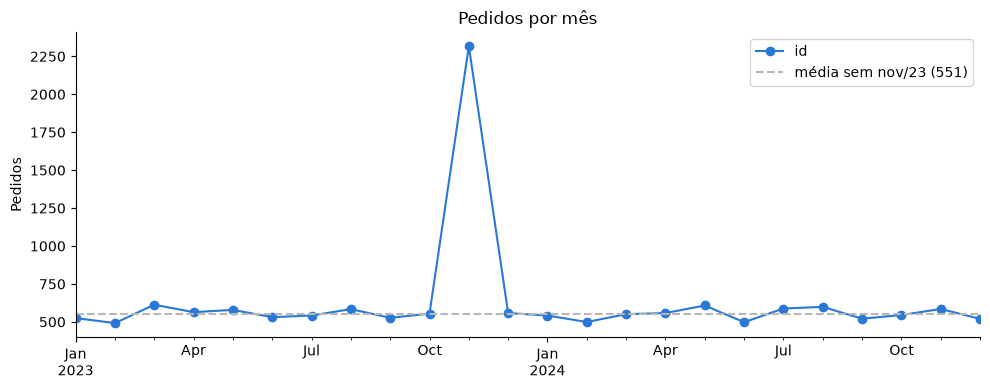

mes
2023-11    2317
2023-03     613
2024-05     608
2024-08     599
2024-07     588
Freq: M, Name: id, dtype: int64

In [13]:
por_mes = pedidos.groupby("mes")["id"].count()
media_normal = por_mes.drop(pd.Period("2023-11")).mean()
print(f"Média mensal (sem nov/2023): {media_normal:.0f} pedidos")

ax = por_mes.plot(marker="o", color=AZUL, figsize=(10, 4))
ax.axhline(media_normal, color=CINZA, linestyle="--", label=f"média sem nov/23 ({media_normal:.0f})")
ax.set_title("Pedidos por mês")
ax.set_ylabel("Pedidos")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
plt.show()

por_mes.sort_values(ascending=False).head(5)

In [14]:
# Separando novembro para analisar
nov = pedidos[pedidos["mes"] == pd.Period("2023-11")]
outros = pedidos[pedidos["mes"] != pd.Period("2023-11")]

print("Pedidos na 1ª quinzena de nov/23:", (nov["data_pedido"].dt.day <= 15).sum())
print("Pedidos na 2ª quinzena de nov/23:", (nov["data_pedido"].dt.day > 15).sum())
print(f"% com cupom — nov/23: {(nov['cupom_desconto'] == 'sim').mean():.1%} | demais meses: {(outros['cupom_desconto'] == 'sim').mean():.1%}")
print(f"Ticket médio — nov/23: R$ {nov['valor_total'].mean():.0f} | demais meses: R$ {outros['valor_total'].mean():.0f}")

Pedidos na 1ª quinzena de nov/23: 1141
Pedidos na 2ª quinzena de nov/23: 1176
% com cupom — nov/23: 34.4% | demais meses: 35.3%
Ticket médio — nov/23: R$ 2528 | demais meses: R$ 2583


**Resposta**

O volume de pedidos é bastante estavel ao longo dos dois anos, com exceção de um único mês. Na maior parte do tempo a OrbitShop recebe cerca de 550 pedidos por mês, como mostra a linha tracejada do gráfico, e não há sinal de crescimento de 2023 para 2024.

O grande pico acontece em novembro de 2023, com 2.317 pedidos, mais de quatro vezes a média. A primeira explicação que vem à cabeça é a Black Friday, então testei essa hipotese. Se fosse Black Friday, os pedidos deveriam se concentrar no fim do mês e o uso de cupom deveria subir. Não é o que acontece. Os pedidos estão divididos de forma igual entre a primeira quinzena (1.141) e a segunda (1.176), e o uso de cupom (34,4% contra 35,3%) e o ticket médio (R$2.528 contra R$2.583) ficam iguais aos dos outros meses. Por isso, a hipótese que considero mais provável é um erro na carga dos dados, como pedidos duplicados ou de outro período gravados com a data de novembro de 2023. Isso precisa ser confirmado com o time de dados, e é esse mês que faz 2023 ter mais pedidos que 2024.

Além dele, há dois picos menores, em março de 2023, com 613 pedidos, e em maio de 2024, com 608, ambos só uns 10% acima da média. Para março, a hipótese é o Dia do Consumidor, em 15 de março, e para maio, o Dia das Mães. Por fim, chama atençao que não exista nenhum pico no Natal, já que dezembro é um mês comum nos dois anos.

## Q6. O `valor_total` bate com a soma dos itens?

In [15]:
soma_itens = itens.groupby("pedido_id")["valor_item"].sum().rename("soma_itens")
comparacao = pedidos.merge(soma_itens, left_on="id", right_index=True)
comparacao = comparacao.dropna(subset=["valor_total"])  # 79 pedidos sem valor_total

comparacao["diferenca"] = comparacao["valor_total"] - comparacao["soma_itens"]
bate = (comparacao["diferenca"].abs() / comparacao["soma_itens"]) < 0.01  # tolerância de 1%

print(f"Pedidos que batem (±1%): {bate.mean():.1%}")
print(f"Soma de valor_total:   R$ {comparacao['valor_total'].sum() / 1e6:.1f} mi")
print(f"Soma dos itens:        R$ {comparacao['soma_itens'].sum() / 1e6:.1f} mi")

Pedidos que batem (±1%): 0.2%
Soma de valor_total:   R$ 38.4 mi
Soma dos itens:        R$ 175.9 mi


In [16]:
# Usando o pedido id=1 como exemplo
print(pedidos.loc[pedidos["id"] == 1, ["id", "valor_total"]].to_string(index=False))
itens.loc[itens["pedido_id"] == 1, ["produto_id", "quantidade", "preco_unitario", "desconto_aplicado", "preco_praticado", "valor_item"]]

 id  valor_total
  1       396.51


,produto_id,quantidade,preco_unitario,desconto_aplicado,preco_praticado,valor_item
0,133,4,2828.22,0.19,2290.86,9163.44
1,64,3,915.27,0.21,723.06,2169.18
2,7,1,497.20,0.29,353.01,353.01


In [17]:
# Qual número é coerente com o que a CEO disse: "pedidos B2B valem, em média, 6 vezes mais"?
comparacao = comparacao.merge(clientes[["id", "segmento"]], left_on="cliente_id", right_on="id", suffixes=("", "_cli"))
ticket_seg = comparacao.groupby("segmento")[["valor_total", "soma_itens"]].mean()
ticket_seg.loc["B2B ÷ B2C"] = ticket_seg.loc["B2B"] / ticket_seg.loc["B2C"]
ticket_seg.round(2)

,valor_total,soma_itens
segmento,,
B2B,7778.34,11716.83
B2C,1264.72,11803.65
B2B ÷ B2C,6.15,0.99


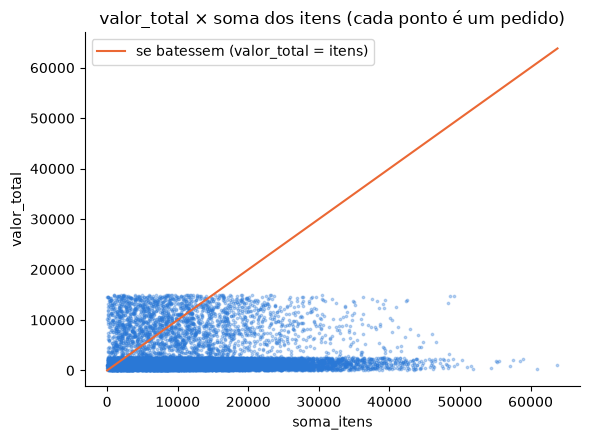

In [18]:
ax = comparacao.plot.scatter(x="soma_itens", y="valor_total", s=3, alpha=0.3, color=AZUL, figsize=(6, 4.5))
limite = comparacao["soma_itens"].max()
ax.plot([0, limite], [0, limite], color=LARANJA, label="se batessem (valor_total = itens)")
ax.set_title("valor_total × soma dos itens (cada ponto é um pedido)")
ax.legend()
plt.tight_layout()
plt.show()

**Resposta**

Não bate. Para cada pedido, somei o valor dos itens (quantidade × preço praticado) e comparei com o `valor_total` registrado na tabela de pedidos. Só 0,2% dos pedidos conciliam, mesmo com uma tolerância de 1%. No total, os itens somam R$175,9 milhões, enquanto o `valor_total` soma R$38,4 milhões. A correlação entre os dois números é praticamente zero, o que o gráfico de dispersão deixa visível, já que os pontos não seguem a linha onde os dois valores seriam iguais. Não se trata de uma diferença de desconto ou arredondamento, os dois campos simplesmente não tem relação.

O pedido 1 é um bom exemplo. Seus três itens somam R$11.686, mas o `valor_total` registrado é de apenas R$397, um valor que não sai de nenhuma conta possível com esses itens.

Eu levaria o `valor_total` ao conselho, deixando a ressalva calra. O principal motivo é que ele é o único coerente com o que a empresa sabe de si mesma. A CEO disse que os pedidos B2B valem, em média, seis vezes mais que os B2C, e pelo `valor_total` essa relação é de 6,15. Pela soma dos itens, B2B e B2C teriam praticamente o mesmo ticket (0,99), o que contradiz a própria empresa. Além disso, o `valor_total` é o valor registrado no pedido, ou seja, o que foi cobrado, e está preenchido em 99,5% dos casos. A soma dos itens daria um ticket médio de quase R$11.800, pouco realista para um marketplace em que 80% dos clientes são pessoas físicas.

A consequência prática é que os valores por categoria (Q3) devem ser lidos como proporção, não como reais. Antes de levar qualquer valor ao data room, o ideal é conciliar o `valor_total` com o faturamento real, como notas fiscais ou o extrato do meio de pagamento.

## Q7. Fornecedores, avaliações e chamados

In [19]:
# Avaliações por fornecedor
aval_forn = avaliacoes.merge(produtos[["id", "fornecedor"]], left_on="produto_id", right_on="id", suffixes=("", "_prod"))
aval_forn["nota_ruim"] = aval_forn["nota"] <= 2

fornecedores = aval_forn.groupby("fornecedor").agg(
    avaliacoes=("id", "count"),
    nota_media=("nota", "mean"),
    pct_notas_1_ou_2=("nota_ruim", "mean"),
)
fornecedores["pct_notas_1_ou_2"] *= 100
fornecedores.sort_values("nota_media").round(2)

,avaliacoes,nota_media,pct_notas_1_ou_2
fornecedor,,,
DeltaFornece ME,985,2.30,59.90
SulFornece SA,845,3.62,22.37
NorteImport Ltda,824,3.66,22.09
TechBrasil Ltda,1027,3.74,20.25
AlphaSupply,684,3.80,18.13
GlobalBR Comércio,912,3.80,17.43
FornecedorX,789,3.81,18.76
MegaDistribuidora,1241,3.82,17.73
MarcoPolo Distribuição,693,3.84,17.75


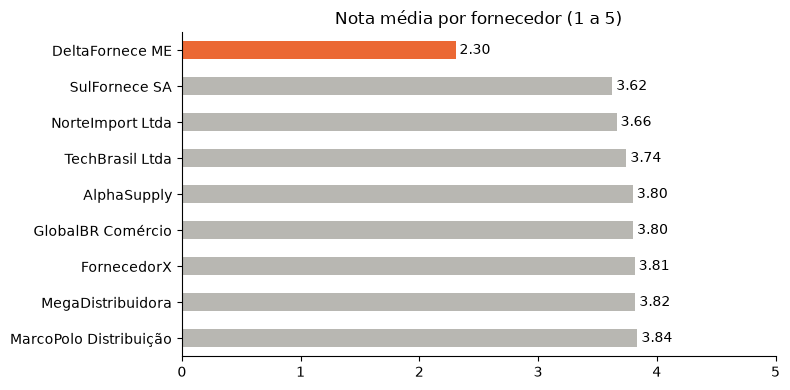

In [20]:
t = fornecedores.sort_values("nota_media", ascending=False)
cores = [LARANJA if f == "DeltaFornece ME" else CINZA for f in t.index]
ax = t["nota_media"].plot.barh(color=cores, figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt=" %.2f")
ax.set_title("Nota média por fornecedor (1 a 5)")
ax.set_xlim(0, 5)
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Os chamados de suporte

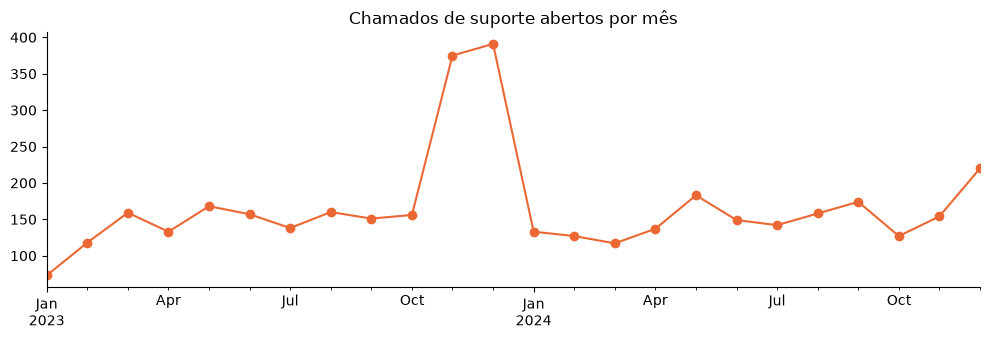

In [21]:
# Chamados abertos por mês
tickets_mes = tickets.groupby(tickets["data_abertura"].dt.to_period("M"))["id"].count()

ax = tickets_mes.plot(marker="o", color=LARANJA, figsize=(10, 3.5))
ax.set_title("Chamados de suporte abertos por mês")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [22]:
# Para separar 'mais problemas' de 'mais pedidos' fiz chamados por 100 pedidos, pelo mês da COMPRA
tickets_ped = tickets.merge(pedidos[["id", "mes"]], left_on="pedido_id", right_on="id", suffixes=("", "_ped"))
chamados_por_100 = tickets_ped.groupby("mes")["id"].count() / pedidos.groupby("mes")["id"].count() * 100
print(f"Chamados por 100 pedidos (mínimo): {chamados_por_100.min():.1f} | máximo: {chamados_por_100.max():.1f} | média: {chamados_por_100.mean():.1f}")
print(f"Nov/2023 (mês do pico de pedidos): {chamados_por_100[pd.Period('2023-11')]:.1f}")

Chamados por 100 pedidos (mínimo): 22.6 | máximo: 29.5 | média: 26.8
Nov/2023 (mês do pico de pedidos): 26.0


In [23]:
# Os pedidos com produtos da DeltaFornece geram mais chamados?
itens_forn = itens.merge(produtos[["id", "fornecedor"]], left_on="produto_id", right_on="id", suffixes=("", "_prod"))
pedidos_delta = itens_forn.loc[itens_forn["fornecedor"] == "DeltaFornece ME", "pedido_id"].unique()

tem_delta = pedidos["id"].isin(pedidos_delta)
teve_chamado = pedidos["id"].isin(tickets["pedido_id"])
pd.Series({
    "com produto DeltaFornece": teve_chamado[tem_delta].mean() * 100,
    "sem produto DeltaFornece": teve_chamado[~tem_delta].mean() * 100,
}, name="% de pedidos com chamado").round(1)

com produto DeltaFornece    26.0
sem produto DeltaFornece    26.9
Name: % de pedidos com chamado, dtype: float64

**Resposta**

Sim, um fornecedor se comporta bem pior que os demais. A DeltaFornece ME tem nota média de 2,30, enquanto os outros ficam entre 3,6 e 3,8, e 60% das avaliações dos produtos dela são notas 1 ou 2, contra cerca de 19% nos outros fornecedores.

Mesmo assim, ela não explica o aumento de chamados, nem sozinha nem como parte relevante da história. A última tabela mostra que 26,0% dos pedidos com produtos dela abrem chamado, praticamente o mesmo que os pedidos sem produtos dela (26,9%). Ou seja, a avaliação ruim não está virando mais trabalho para o suporte.

O que explica o pico de chamados de novembro e dezembro de 2023, visível no gráfico de chamados por mês, é o próprio pico de pedidos de novembro de 2023 que vimos na Q5. Para separar "mais problemas" de "mais pedidos", calculei quantos chamados surgem a cada 100 pedidos de cada mês. Esse número fica estavel o tempo todo, entre 23 e 30 e perto de 27 na média, e em novembro de 2023 fica em 26. Houve mais chamados porque houve mais pedidos, e não porque a qualidade piorou.

A DeltaFornece é, portanto, um problema de reputação, porque uma avaliação ruim afasta quem está pensando em comprar, mas não é a causa dos chamados. Uma curiosidade é que a FornecedorX, que pelo nome parece suspeita, está entre as mais bem avaliadas.

## Q8. Uma ação imediata

In [24]:
paid = ped_cli["canal_aquisicao"] == "paid_search"
taxa_paid = ped_cli.loc[paid, "cancelado"].mean()
taxa_outros = ped_cli.loc[~paid, "cancelado"].mean()

# Quantos cancelamentos a menos se paid search cancelasse como os outros canais?
cancel_a_menos = paid.sum() * (taxa_paid - taxa_outros)
ticket_cancelado_paid = ped_cli.loc[paid & ped_cli["cancelado"], "valor_total"].mean()
nova_taxa = (ped_cli["cancelado"].sum() - cancel_a_menos) / len(ped_cli)
entregue_paid = ped_cli.loc[paid & (ped_cli["status"] == "entregue"), "valor_total"].sum()

print(f"Taxa paid search: {taxa_paid:.1%}, demais canais: {taxa_outros:.1%}")
print(f"Cancelamentos a menos (2 anos): {cancel_a_menos:.0f}")
print(f"Valor desses pedidos: R$ {cancel_a_menos * ticket_cancelado_paid / 1e6:.1f} mi")
print(f"Taxa total: {ped_cli['cancelado'].mean():.1%} nova: {nova_taxa:.1%}")
print(f"Vendas entregues via paid search (o que fica em risco): R$ {entregue_paid / 1e6:.1f} mi")

Taxa paid search: 30.7%, demais canais: 11.9%
Cancelamentos a menos (2 anos): 745
Valor desses pedidos: R$ 2.0 mi
Taxa total: 16.9% nova: 11.9%
Vendas entregues via paid search (o que fica em risco): R$ 5.6 mi


**Resposta**

A ação que eu recomendo ao conselho é revisar, em até 30 dias, todo o caminho do cliente que chega por paid search, olhando o que os anúncios prometem, como funciona o checkout e como os pagamentos são aprovados, sem aumentar a verba desse canal até a revisão terminar.

Escolho essa açao porque é o maior problema que encontramos e o único com uma origem clara. Os clientes que vêm de paid search cancelam 30,7% dos pedidos, contra 11,9% nos outros canais, e mesmo representando só 26% dos pedidos eles respondem por quase metade de todos os cancelamentos. O cálculo acima estima o ganho. Se esse canal cancelasse no mesmo nível dos outros, seriam cerca de 745 cancelamentos a menos em dois anos, o equivalente a uns R$2 milhões em pedidos, e a taxa de cancelamento da empresa cairia de 16,9% para 11,9%. Esse é justamente o número que responde à preocupação do fundo.

Ao escolher esse caminho, a empresa abre mão de algumas coisas. Ela adia qualquer medida sobre a DeltaFornece, que tem a pior avaliação entre os fornecedores, deixa de crescer por mídia paga no curto prazo e corre o risco de perder parte dos R$5,6 milhões em vendas entregues que vieram desse canal, caso a revisão leve a cortar campanhas.

## Q9. O que os dados não respondem

A principal pergunta que não consegui responder é por que os clientes que chegam por paid search cancelam tanto. A base mostra que eles cancelam muito mais, mas não traz o motivo, a data nem quem fez o cancelamento, então não dá para saber se é o cliente desistindo, a loja cancelando por falta de estoque ou o antifraude recusando o pagamento.

Antes de assinar a recomendação, eu pediria ao time de dados justamente essas informações para cada pedido cancelado, porque a solução muda muito dependendo da cuasa. Também pediria uma explicação para novembro de 2023, para entender se aqueles 2.317 pedidos são reais ou se foram duplicados ou gravados com a data errada, já que esse mês distorce qualquer comparação entre os dois anos. Outro pedido seria o faturamento real da empresa, com as notas fiscais ou o extrato do meio de pagamento, para confirmar que o `valor_total` é mesmo o número certo a levar ao conselho. Eu ainda pediria quanto a empresa gasta com mídia paga em cada campanha, para saber se o canal compensa mesmo cancelando 31% dos pedidos. Por fim, pediria que os pedidos antigos que ainda aparecem como "em trânsito" fossem atualizados, porque eles mudam a taxa de cancelamento conforme a forma de calcular.

## Registro de uso de IA

*Ajustar com a experiência real.*

- Usei o ferramentar de IA para estruturar o notebook, gerar código de tabelas e gráficos, relembrar funções e lógicas do Pandas e revisar textos.
- **Erro da IA que corrigi:** a primeira versão aplicava `desconto_aplicado` sobre `preco_praticado`, descontando duas vezes. Conferindo o pedido 1 à mão, vi que o preço praticado já vem com desconto.
- **Simplificações que rejeitei:** chamar o pico de nov/23 de Black Friday sem testar; culpar o pior fornecedor pelos chamados; tratar a soma dos itens como verdade só por ser mais detalhada.